# Optimización estratégica e integración final del modelo neuronal

## Importación de datos - MINST

### Cambio y escalamiento del conjunto de datos

Para esta nueva etapa del proyecto se utilizará un conjunto de datos diferente al empleado anteriormente. En el proyecto inicial se trabajó con un dataset artificial compuesto por puntos distribuidos en forma de anillos pertenecientes a dos clases diferentes. Este conjunto permitió demostrar una de las principales limitaciones de los modelos lineales: la dificultad para separar correctamente clases que no son linealmente separables. A partir de este problema se justificó la necesidad de utilizar modelos con mayor capacidad, como un **perceptrón multicapa (MLP)**.

Sin embargo, en esta etapa se busca ampliar el alcance del MLP y llevarlo hacia un problema más cercano a los escenarios habituales del aprendizaje profundo. Por esta razón, no solo se incrementará la complejidad del modelo, sino también la del conjunto de datos. La intención es trabajar con un problema de mayor escala que permita identificar algunas de las limitaciones que pueden aparecer al utilizar redes neuronales y, posteriormente, aplicar diferentes estrategias para abordarlas y optimizar su funcionamiento.

Para ello se utilizará **MNIST**, uno de los conjuntos de datos más conocidos en problemas de clasificación de imágenes. MNIST contiene **70.000 imágenes de dígitos escritos a mano**, correspondientes a los números del 0 al 9. Cada ejemplo está compuesto por una imagen y su respectiva etiqueta, que indica cuál es el dígito representado.

Las imágenes tienen una resolución de **28 × 28 píxeles**, por lo que cada imagen puede representarse mediante **784 valores de entrada**, correspondientes a los píxeles. El objetivo del modelo será aprender la relación entre estos valores y la etiqueta correspondiente para identificar correctamente qué número representa cada imagen.

El uso de MNIST permitirá aumentar considerablemente la complejidad respecto al problema anterior y, al mismo tiempo, observar de manera práctica diferentes desafíos asociados con el entrenamiento de un MLP. A medida que estos problemas aparezcan, se podrán analizar y aplicar estrategias de optimización para mejorar el desempeño del modelo.

In [1]:
import numpy as np
from tensorflow.keras.datasets import mnist
from sklearn.model_selection import train_test_split

# Semilla para que la inicialización de pesos y el barajado sean reproducibles entre corridas
np.random.seed(42)

# 1. Cargar los datos de MNIST
(X_train_full, y_train_full), (X_test_full, y_test_full) = mnist.load_data()

# Combinar los conjuntos de entrenamiento y prueba para un preprocesamiento más sencillo
X_full = np.concatenate((X_train_full, X_test_full), axis=0)
y_full = np.concatenate((y_train_full, y_test_full), axis=0)

print(f"Dimensiones del conjunto de datos completo original (imágenes): {X_full.shape}")
print(f"Dimensiones del conjunto de datos completo original (etiquetas): {y_full.shape}")

# 2. Preprocesar imágenes:
#    a. Normalizar los valores de los píxeles para que estén entre 0 y 1
X_full_normalized = X_full / 255.0

#    b. Aplanar las imágenes en vectores unidimensionales
#    Cada imagen es de 28x28, así que se aplana a 784 características
X_full_flattened = X_full_normalized.reshape(X_full_normalized.shape[0], -1)

print(f"Dimensiones del conjunto de datos aplanado y normalizado: {X_full_flattened.shape}")

# 3. Mantener las etiquetas originales de 0 a 9
print(f"Dimensiones de las etiquetas originales: {y_full.shape}")
print(f"Ejemplo de etiquetas originales: {y_full[:10]}")

# 4. Realizar la división 80/20 de entrenamiento y prueba (estratificada)
X_train, X_test, y_train, y_test = train_test_split(
    X_full_flattened, y_full, test_size=0.2, random_state=42, stratify=y_full
)

print(f"Dimensiones de X_train: {X_train.shape}")
print(f"Dimensiones de y_train: {y_train.shape}")
print(f"Dimensiones de X_test: {X_test.shape}")
print(f"Dimensiones de y_test: {y_test.shape}")

2026-11-06 19:20:04.810684: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


       0/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step

   32768/11490434 ━━━━━━━━━━━━━━━━━━━━ 22s 2us/step

   65536/11490434 ━━━━━━━━━━━━━━━━━━━━ 21s 2us/step

   81920/11490434 ━━━━━━━━━━━━━━━━━━━━ 25s 2us/step

  147456/11490434 ━━━━━━━━━━━━━━━━━━━━ 18s 2us/step

... (10 outputs left out)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Dimensiones del conjunto de datos completo original (imágenes): (70000, 28, 28)
Dimensiones del conjunto de datos completo original (etiquetas): (70000,)


Dimensiones del conjunto de datos aplanado y normalizado: (70000, 784)
Dimensiones de las etiquetas originales: (70000,)
Ejemplo de etiquetas originales: [5 0 4 1 9 2 1 3 1 4]


Dimensiones de X_train: (56000, 784)
Dimensiones de y_train: (56000,)
Dimensiones de X_test: (14000, 784)
Dimensiones de y_test: (14000,)


## Modelo Base (Mejor configuración del taller anterior)

En el taller anterior se partió de un MLP de 32x32 neuronas entrenado con SGD puro y, a través de cuatro experimentos (arquitectura, regularización, optimizadores y técnicas combinadas), se identificó como mejor configuración global un **MLP con dos capas ocultas de 64 neuronas**, entrenado con **momentum (β = 0.9)** y **sin regularización**, que alcanzó una accuracy de **97.87%** y un F1-score ponderado de **0.9787** sobre el conjunto de prueba.

Para esta nueva etapa ese modelo pasa a ser el **baseline**: todas las mejoras posteriores se medirán frente a él. Se mantienen los mismos elementos estructurales definidos anteriormente:

### Funciones de activación y capa de salida
ReLU en las capas ocultas y softmax en la capa de salida, que convierte las diez salidas de la red en una distribución de probabilidades sobre los dígitos del 0 al 9.

### Función de pérdida y backpropagation
Entropía cruzada categórica multiclase, cuya derivada combinada con softmax en la capa de salida se reduce a $\hat{y} - y$.

### Optimizador
Descenso de gradiente con momentum sobre mini-lotes de 32 muestras:

$$v_t = \beta \, v_{t-1} - \eta \, \nabla_\theta J(\theta_t), \qquad \theta_{t+1} = \theta_t + v_t$$

### Codificación One-Hot
Las etiquetas se transforman a vectores de diez posiciones para compararse directamente con las diez salidas de la red.

Se reutiliza la clase `MLP_Combined` del Experimento 4, ya que admite optimizadores y regularización y servirá para las mejoras siguientes. Respecto a la versión anterior se hicieron dos ajustes: el conjunto de evaluación se pasa explícitamente a `train` (antes se leía de variables globales) y en cada época se registra también la accuracy de entrenamiento y prueba. Además, el contador de Adam ahora aumenta en cada actualización y no una vez por época, como corresponde a la corrección de sesgo.

In [2]:
import numpy as np

class MLP_Combined:
    def __init__(self, input_size, hidden_layers_sizes, output_size,
                 optimizer_type='sgd', batch_size=32,
                 momentum_beta=0.9, adam_beta1=0.9, adam_beta2=0.999, adam_epsilon=1e-8,
                 regularization_type='none', lambda_reg=0.0):
        self.input_size = input_size
        self.hidden_layers_sizes = hidden_layers_sizes
        self.output_size = output_size
        self.optimizer_type = optimizer_type
        self.batch_size = batch_size
        self.momentum_beta = momentum_beta
        self.adam_beta1 = adam_beta1
        self.adam_beta2 = adam_beta2
        self.adam_epsilon = adam_epsilon
        self.regularization_type = regularization_type
        self.lambda_reg = lambda_reg

        self.weights = []
        self.biases = []
        self.activations = []

        layer_sizes = [input_size] + hidden_layers_sizes + [output_size]

        for i in range(len(layer_sizes) - 1):
            # He initialization para pesos (adecuado para ReLU)
            w = np.random.randn(layer_sizes[i], layer_sizes[i+1]) * np.sqrt(2. / layer_sizes[i])
            b = np.zeros((1, layer_sizes[i+1]))
            self.weights.append(w)
            self.biases.append(b)

            if i < len(layer_sizes) - 2:
                self.activations.append(self.relu)
            else:
                self.activations.append(self.softmax)

        # Inicializar parámetros específicos del optimizador
        if self.optimizer_type == 'momentum':
            self.v_weights = [np.zeros_like(w) for w in self.weights]
            self.v_biases = [np.zeros_like(b) for b in self.biases]
        elif self.optimizer_type == 'adam':
            self.m_weights = [np.zeros_like(w) for w in self.weights]
            self.v_weights_adam = [np.zeros_like(w) for w in self.weights]
            self.m_biases = [np.zeros_like(b) for b in self.biases]
            self.v_biases_adam = [np.zeros_like(b) for b in self.biases]
            self.t = 0 # Contador de actualizaciones para la corrección de sesgo en Adam

    def relu(self, x):
        return np.maximum(0, x)

    def relu_derivative(self, x):
        return (x > 0).astype(float)

    def softmax(self, x):
        exp_x = np.exp(x - np.max(x, axis=1, keepdims=True))
        return exp_x / np.sum(exp_x, axis=1, keepdims=True)

    def forward(self, X):
        if X.ndim == 1:
            X = X.reshape(1, -1)
        A = X
        activations_cache = [A]
        Z_cache = []

        for i in range(len(self.weights)):
            Z = np.dot(A, self.weights[i]) + self.biases[i]
            A = self.activations[i](Z)

            Z_cache.append(Z)
            activations_cache.append(A)
        return A, {'Z': Z_cache, 'A': activations_cache}

    def compute_loss(self, y_true, y_pred):
        y_pred = np.clip(y_pred, 1e-10, 1 - 1e-10)
        loss = -np.sum(y_true * np.log(y_pred)) / y_true.shape[0]

        # Añadir término de regularización si lambda_reg > 0
        if self.lambda_reg > 0:
            reg_penalty = 0
            if self.regularization_type == 'l1':
                for w in self.weights:
                    reg_penalty += np.sum(np.abs(w))
            elif self.regularization_type == 'l2':
                for w in self.weights:
                    reg_penalty += np.sum(w**2)
            loss += (self.lambda_reg / (2 * y_true.shape[0])) * reg_penalty

        return loss

    def backward(self, X, y_true, y_pred, cache):
        grads_W = [np.zeros_like(w) for w in self.weights]
        grads_b = [np.zeros_like(b) for b in self.biases]
        m = X.shape[0]

        A_cache = cache['A']
        Z_cache = cache['Z']

        # dZ_L = y_pred - y_true para softmax con entropía cruzada categórica
        dZ = (y_pred - y_true) / m

        grads_W[-1] = np.dot(A_cache[-2].T, dZ)
        grads_b[-1] = np.sum(dZ, axis=0, keepdims=True)

        for i in reversed(range(len(self.weights) - 1)):
            dA_prev = np.dot(dZ, self.weights[i+1].T)
            dZ = dA_prev * self.relu_derivative(Z_cache[i])

            grads_W[i] = np.dot(A_cache[i].T, dZ)
            grads_b[i] = np.sum(dZ, axis=0, keepdims=True)

        # Añadir gradiente de regularización a todas las capas
        if self.lambda_reg > 0:
            for i in range(len(self.weights)):
                if self.regularization_type == 'l1':
                    grads_W[i] += (self.lambda_reg / m) * np.sign(self.weights[i])
                elif self.regularization_type == 'l2':
                    grads_W[i] += (self.lambda_reg / m) * self.weights[i]

        return grads_W, grads_b

    def update_parameters(self, grads_W, grads_b, learning_rate):
        if self.optimizer_type == 'adam':
            self.t += 1

        for j in range(len(self.weights)):
            if self.optimizer_type == 'sgd':
                self.weights[j] -= learning_rate * grads_W[j]
                self.biases[j] -= learning_rate * grads_b[j]
            elif self.optimizer_type == 'momentum':
                self.v_weights[j] = self.momentum_beta * self.v_weights[j] - learning_rate * grads_W[j]
                self.v_biases[j] = self.momentum_beta * self.v_biases[j] - learning_rate * grads_b[j]
                self.weights[j] += self.v_weights[j]
                self.biases[j] += self.v_biases[j]
            elif self.optimizer_type == 'adam':
                self.m_weights[j] = self.adam_beta1 * self.m_weights[j] + (1 - self.adam_beta1) * grads_W[j]
                self.m_biases[j] = self.adam_beta1 * self.m_biases[j] + (1 - self.adam_beta1) * grads_b[j]

                self.v_weights_adam[j] = self.adam_beta2 * self.v_weights_adam[j] + (1 - self.adam_beta2) * (grads_W[j] ** 2)
                self.v_biases_adam[j] = self.adam_beta2 * self.v_biases_adam[j] + (1 - self.adam_beta2) * (grads_b[j] ** 2)

                m_hat_W = self.m_weights[j] / (1 - self.adam_beta1 ** self.t)
                m_hat_b = self.m_biases[j] / (1 - self.adam_beta1 ** self.t)
                v_hat_W = self.v_weights_adam[j] / (1 - self.adam_beta2 ** self.t)
                v_hat_b = self.v_biases_adam[j] / (1 - self.adam_beta2 ** self.t)

                self.weights[j] -= learning_rate * m_hat_W / (np.sqrt(v_hat_W) + self.adam_epsilon)
                self.biases[j] -= learning_rate * m_hat_b / (np.sqrt(v_hat_b) + self.adam_epsilon)

    def train(self, X_train, y_train, X_val, y_val, epochs, learning_rate, verbose_every=10):
        """
        Entrena con mini-lotes y registra, por época, pérdida y accuracy
        de entrenamiento y del conjunto de evaluación.
        y_train y y_val contienen las etiquetas numéricas originales (0-9).
        """
        y_train_one_hot = np.eye(self.output_size)[y_train]
        y_val_one_hot = np.eye(self.output_size)[y_val]

        num_samples = X_train.shape[0]
        num_batches = int(np.ceil(num_samples / self.batch_size))

        history = {'train_loss': [], 'test_loss': [], 'train_acc': [], 'test_acc': []}

        for epoch in range(epochs):
            indices = np.arange(num_samples)
            np.random.shuffle(indices)

            epoch_train_loss = 0
            epoch_train_correct = 0

            for batch_idx in range(num_batches):
                batch_indices = indices[batch_idx * self.batch_size:(batch_idx + 1) * self.batch_size]
                X_batch = X_train[batch_indices]
                y_batch_one_hot = y_train_one_hot[batch_indices]

                y_pred, cache = self.forward(X_batch)
                epoch_train_loss += self.compute_loss(y_batch_one_hot, y_pred) * X_batch.shape[0]
                epoch_train_correct += np.sum(np.argmax(y_pred, axis=1) == y_train[batch_indices])

                grads_W, grads_b = self.backward(X_batch, y_batch_one_hot, y_pred, cache)
                self.update_parameters(grads_W, grads_b, learning_rate)

            history['train_loss'].append(epoch_train_loss / num_samples)
            history['train_acc'].append(epoch_train_correct / num_samples)

            y_val_pred, _ = self.forward(X_val)
            history['test_loss'].append(self.compute_loss(y_val_one_hot, y_val_pred))
            history['test_acc'].append(np.mean(np.argmax(y_val_pred, axis=1) == y_val))

            if verbose_every and ((epoch + 1) % verbose_every == 0 or epoch == 0 or epoch == epochs - 1):
                print(f"Época {epoch+1}/{epochs}, Pérdida de Entrenamiento: {history['train_loss'][-1]:.4f}, "
                      f"Pérdida de Prueba: {history['test_loss'][-1]:.4f}, Accuracy de Prueba: {history['test_acc'][-1]:.4f}")

        return history

    def predict(self, X):
        y_pred_probs, _ = self.forward(X)
        return np.argmax(y_pred_probs, axis=1)

    def evaluate(self, X_test, y_test):
        accuracy = np.mean(self.predict(X_test) == y_test) * 100
        print(f"Evaluation Accuracy: {accuracy:.2f}%")
        return accuracy

# Entrenamiento del modelo baseline (64x64 + Momentum)

El baseline se entrena con exactamente la misma configuración que obtuvo el mejor resultado en el taller anterior: capas ocultas de **64 y 64 neuronas**, optimizador **momentum (β = 0.9)**, **learning rate de 0.01**, **mini-lotes de 32 muestras** y **sin regularización**.

El único cambio es el número de épocas, que pasa de **30 a 100**. En la curva de pérdida del taller anterior (Anexo E del informe) la pérdida de entrenamiento llegó prácticamente a cero alrededor de la época 25, mientras que la pérdida de prueba se estabilizó cerca de 0.10 y empezó a subir levemente al final. Extender el entrenamiento permite observar si esa tendencia se mantiene, es decir, si con más épocas el modelo sigue memorizando el conjunto de entrenamiento y la pérdida de prueba crece. Este diagnóstico es el punto de partida para justificar las mejoras siguientes.

Además de las métricas finales, se registra la época con menor pérdida de prueba, para medir cuánto se degrada el modelo entre su mejor punto y el final del entrenamiento.

In [3]:
import os
import json
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# 1. Definir parámetros del modelo (mejor configuración del taller anterior)
input_size = X_train.shape[1]          # 784 píxeles (28x28 aplanado)
hidden_layers_sizes = [64, 64]         # Dos capas ocultas de 64 neuronas
output_size = len(np.unique(y_train))  # 10 clases (0-9)
optimizer_type = 'momentum'
momentum_beta = 0.9
batch_size = 32
learning_rate = 0.01
epochs = 100                           # Antes 30

model_name = 'Baseline MLP 64x64 Momentum'

# 2. Instanciar y entrenar el modelo
print(f"Inicializando MLP con input_size={input_size}, hidden_layers_sizes={hidden_layers_sizes}, output_size={output_size}")
baseline_model = MLP_Combined(
    input_size, hidden_layers_sizes, output_size,
    optimizer_type=optimizer_type, batch_size=batch_size, momentum_beta=momentum_beta
)

print(f"\nEntrenando el modelo: {model_name} con {epochs} épocas, learning_rate={learning_rate}, batch_size={batch_size}...")
baseline_history = baseline_model.train(X_train, y_train, X_test, y_test, epochs, learning_rate)
print("\nEntrenamiento completado.\n")

# 3. Evaluar el modelo en el conjunto de prueba
print("Evaluando el modelo en el conjunto de prueba...")
accuracy = baseline_model.evaluate(X_test, y_test)
y_pred_classes_test = baseline_model.predict(X_test)

best_epoch = int(np.argmin(baseline_history['test_loss'])) + 1
print(f"Menor pérdida de prueba: {min(baseline_history['test_loss']):.4f} en la época {best_epoch} "
      f"(accuracy de prueba en esa época: {baseline_history['test_acc'][best_epoch - 1]:.4f})")

Inicializando MLP con input_size=784, hidden_layers_sizes=[64, 64], output_size=10

Entrenando el modelo: Baseline MLP 64x64 Momentum con 100 épocas, learning_rate=0.01, batch_size=32...


Época 1/100, Pérdida de Entrenamiento: 0.2929, Pérdida de Prueba: 0.1783, Accuracy de Prueba: 0.9461


Época 10/100, Pérdida de Entrenamiento: 0.0290, Pérdida de Prueba: 0.0993, Accuracy de Prueba: 0.9722


Época 20/100, Pérdida de Entrenamiento: 0.0045, Pérdida de Prueba: 0.1046, Accuracy de Prueba: 0.9764


Época 30/100, Pérdida de Entrenamiento: 0.0004, Pérdida de Prueba: 0.1111, Accuracy de Prueba: 0.9793


Época 40/100, Pérdida de Entrenamiento: 0.0003, Pérdida de Prueba: 0.1162, Accuracy de Prueba: 0.9784


... (2 outputs left out)

Época 70/100, Pérdida de Entrenamiento: 0.0001, Pérdida de Prueba: 0.1263, Accuracy de Prueba: 0.9787


Época 80/100, Pérdida de Entrenamiento: 0.0001, Pérdida de Prueba: 0.1284, Accuracy de Prueba: 0.9786


Época 90/100, Pérdida de Entrenamiento: 0.0001, Pérdida de Prueba: 0.1305, Accuracy de Prueba: 0.9784


Época 100/100, Pérdida de Entrenamiento: 0.0001, Pérdida de Prueba: 0.1322, Accuracy de Prueba: 0.9787

Entrenamiento completado.

Evaluando el modelo en el conjunto de prueba...
Evaluation Accuracy: 97.87%
Menor pérdida de prueba: 0.0888 en la época 7 (accuracy de prueba en esa época: 0.9743)


In [4]:
# 4. Generar el Informe de Clasificación
print("Informe de Clasificación:")
report = classification_report(y_test, y_pred_classes_test, output_dict=True)
print(classification_report(y_test, y_pred_classes_test, digits=4))

Informe de Clasificación:
              precision    recall  f1-score   support

           0     0.9779    0.9928    0.9853      1381
           1     0.9848    0.9892    0.9870      1575
           2     0.9842    0.9814    0.9828      1398
           3     0.9838    0.9762    0.9800      1428
           4     0.9807    0.9663    0.9734      1365
           5     0.9756    0.9818    0.9787      1263
           6     0.9825    0.9825    0.9825      1375
           7     0.9795    0.9801    0.9798      1459
           8     0.9765    0.9722    0.9743      1365
           9     0.9606    0.9633    0.9620      1391

    accuracy                         0.9787     14000
   macro avg     0.9786    0.9786    0.9786     14000
weighted avg     0.9787    0.9787    0.9787     14000



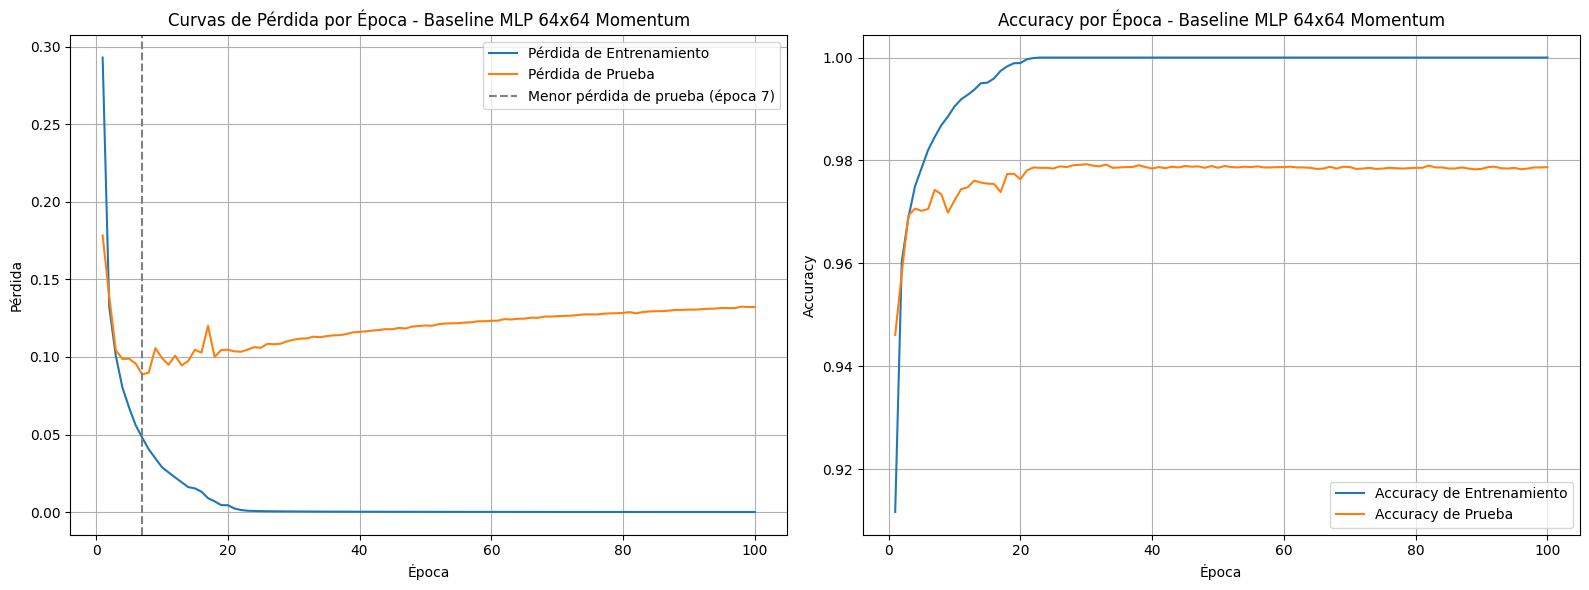

In [5]:
# 5. Graficar las Curvas de Pérdida y Accuracy
epochs_range = range(1, epochs + 1)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].plot(epochs_range, baseline_history['train_loss'], label='Pérdida de Entrenamiento')
axes[0].plot(epochs_range, baseline_history['test_loss'], label='Pérdida de Prueba')
axes[0].axvline(best_epoch, color='gray', linestyle='--', label=f'Menor pérdida de prueba (época {best_epoch})')
axes[0].set_title(f'Curvas de Pérdida por Época - {model_name}')
axes[0].set_xlabel('Época')
axes[0].set_ylabel('Pérdida')
axes[0].legend()
axes[0].grid(True)

axes[1].plot(epochs_range, baseline_history['train_acc'], label='Accuracy de Entrenamiento')
axes[1].plot(epochs_range, baseline_history['test_acc'], label='Accuracy de Prueba')
axes[1].set_title(f'Accuracy por Época - {model_name}')
axes[1].set_xlabel('Época')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

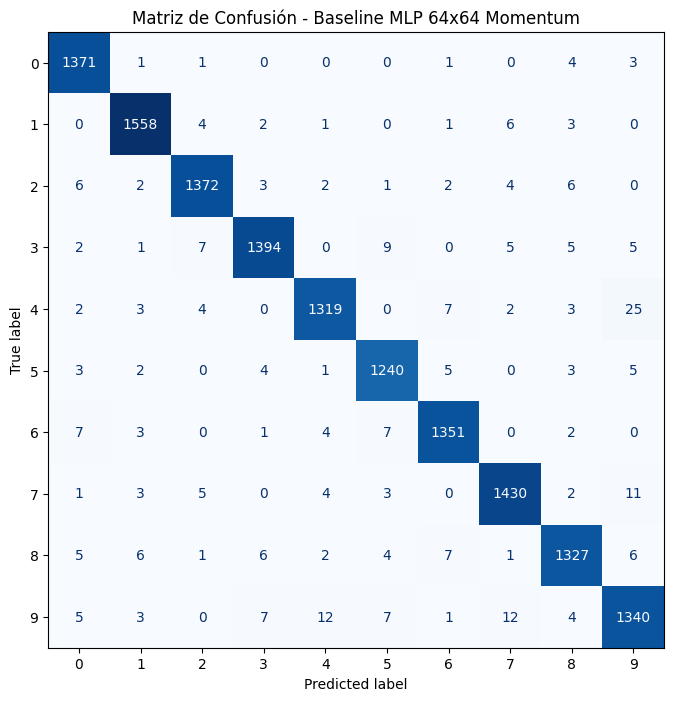

In [6]:
# 6. Matriz de confusión
cm = confusion_matrix(y_test, y_pred_classes_test)
fig, ax = plt.subplots(figsize=(8, 8))
ConfusionMatrixDisplay(cm, display_labels=range(10)).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title(f'Matriz de Confusión - {model_name}')
plt.show()

In [7]:
# 7. Almacenar Estadísticas en un DataFrame y guardarlas en disco
model_performance_df = pd.DataFrame([{
    'Model Name': model_name,
    'Epochs': epochs,
    'Accuracy': accuracy / 100.0,
    'Precision (weighted)': report['weighted avg']['precision'],
    'Recall (weighted)': report['weighted avg']['recall'],
    'F1-score (weighted)': report['weighted avg']['f1-score'],
    'Training Loss': baseline_history['train_loss'][-1],
    'Test Loss': baseline_history['test_loss'][-1],
    'Best Epoch (min Test Loss)': best_epoch,
    'Min Test Loss': baseline_history['test_loss'][best_epoch - 1]
}])

print("DataFrame de rendimiento del modelo:\n")
print(model_performance_df.T)

results_dir = 'resultados'
os.makedirs(results_dir, exist_ok=True)

# Métricas finales (se irán agregando filas con cada mejora)
model_performance_df.to_csv(os.path.join(results_dir, 'model_performance.csv'), index=False)

# Historial por época del baseline
pd.DataFrame(baseline_history, index=pd.Index(epochs_range, name='epoch')).to_csv(
    os.path.join(results_dir, 'baseline_history.csv'))

# Informe de clasificación por clase y matriz de confusión
with open(os.path.join(results_dir, 'baseline_classification_report.json'), 'w') as f:
    json.dump(report, f, indent=2)
np.savetxt(os.path.join(results_dir, 'baseline_confusion_matrix.csv'), cm, fmt='%d', delimiter=',')

# Pesos y sesgos entrenados, para poder recargar el baseline sin reentrenar
np.savez(os.path.join(results_dir, 'baseline_weights.npz'),
         **{f'W{i}': w for i, w in enumerate(baseline_model.weights)},
         **{f'b{i}': b for i, b in enumerate(baseline_model.biases)})

print(f"\nResultados guardados en la carpeta '{results_dir}/'")

DataFrame de rendimiento del modelo:

                                                      0
Model Name                  Baseline MLP 64x64 Momentum
Epochs                                              100
Accuracy                                       0.978714
Precision (weighted)                           0.978727
Recall (weighted)                              0.978714
F1-score (weighted)                            0.978706
Training Loss                                  0.000077
Test Loss                                       0.13216
Best Epoch (min Test Loss)                            7
Min Test Loss                                  0.088826

Resultados guardados en la carpeta 'resultados/'
